In [1]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244080129
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp01
[学号] 20244080129
[机器指纹] eff28411a62a643f
[RUN_ID] 20244080129-eff28411a62a643f


本次实验围绕随机矩阵理论中的半圆定律（Wigner Semicircle Law）展开，完整实现了从数学公式到数值模拟再到可视化的过程。

首先，任务 1 将理论密度函数 f(x) 转化为 wigner_density 函数，利用 numpy 的向量化操作（np.asarray 和掩码 mask）同时兼容标量和数组输入，提高了函数的通用性。

任务 2 根据 Wigner 矩阵的定义，利用 numpy 生成均值为 0、标准差为 1/√n 的正态随机数，通过“上三角转置相加”的技巧高效构造出对称矩阵，并加入了严格的参数异常检查。

任务 3 调用 np.linalg.eigvalsh 专门求解实对称矩阵的特征值，比通用求解器更快、更稳定，并对其排序返回。

任务 4 将计算与绘图结合，通过 matplotlib 绘制了四个不同阶数 n 的直方图（设置 density=True 使其与概率密度曲线在同一尺度下比对）。在图表中可以直观观察到，随着矩阵维度 n 的增大（如 n=1000），特征值的分布越来越平滑，并完美贴合红色的半圆解析曲线，体现了随机矩阵的普适性。

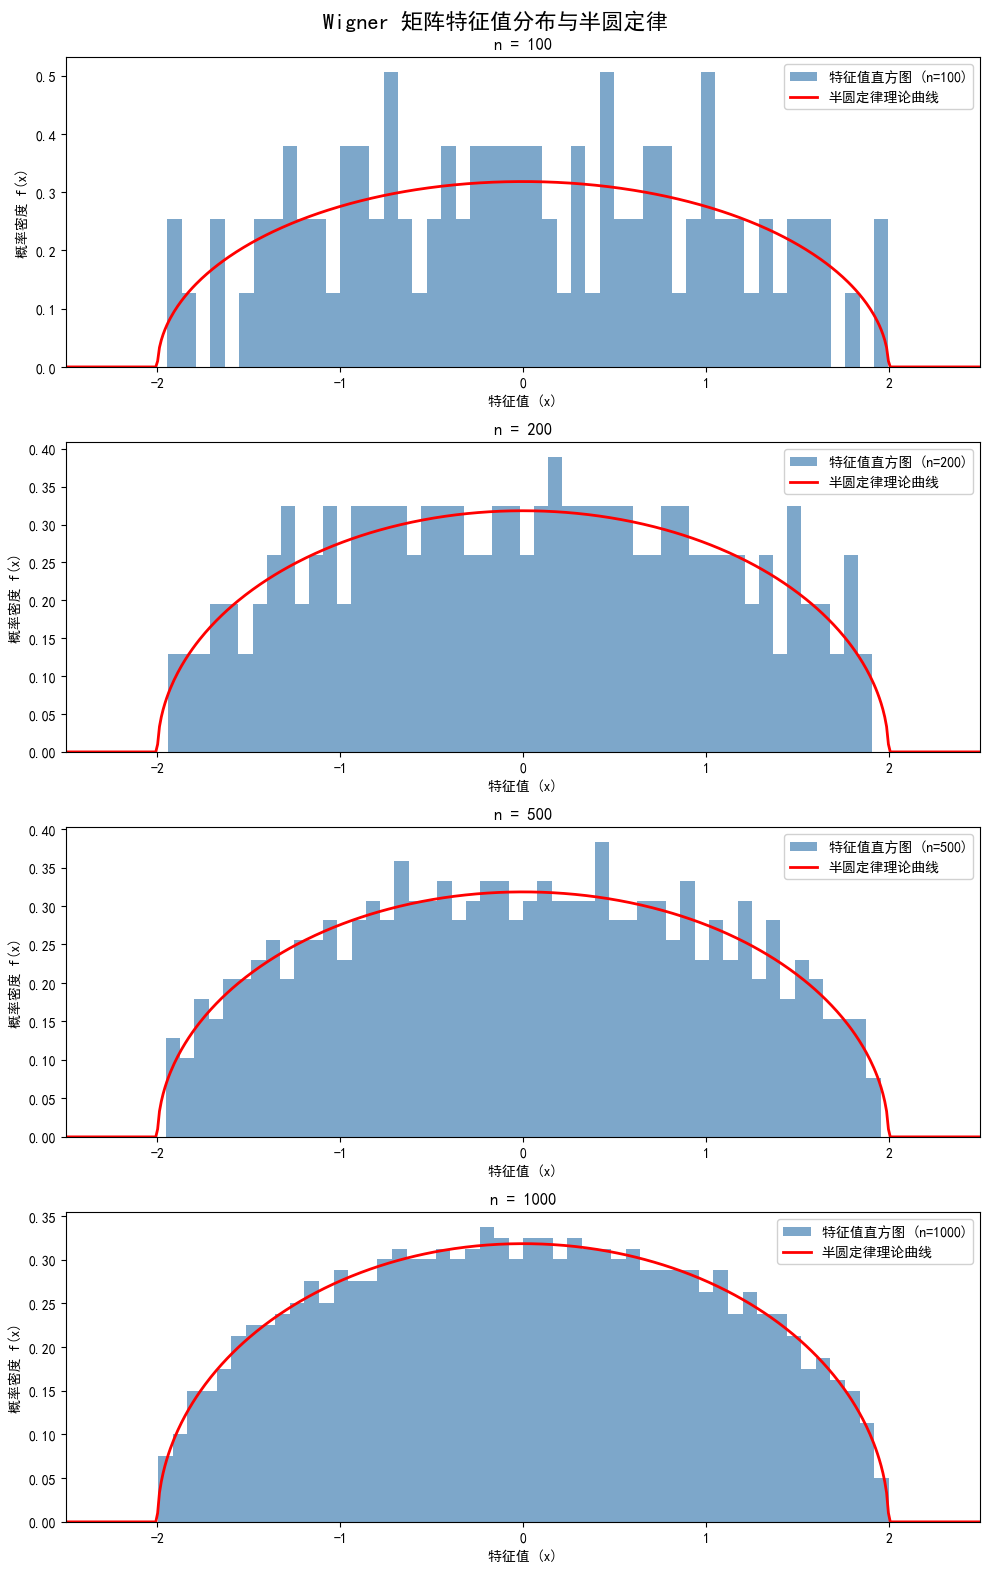

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 解决图表中文显示为方块的问题
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows用黑体，Mac可用 'Arial Unicode MS'
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号

# ==================== 任务 1 ====================
def wigner_density(x):
    x = np.asarray(x, dtype=float)
    density = np.zeros_like(x)
    mask = np.abs(x) <= 2
    density[mask] = (1 / (2 * np.pi)) * np.sqrt(4 - x[mask]**2)
    return density.item() if density.ndim == 0 else density

# ==================== 任务 2 ====================
def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n 必须是正整数")
    std_dev = 1 / np.sqrt(n)
    upper_triangular = np.random.normal(loc=0.0, scale=std_dev, size=(n, n))
    strict_upper = np.triu(upper_triangular, k=1)
    Z = strict_upper + strict_upper.T
    diag_elements = np.random.normal(loc=0.0, scale=std_dev, size=n)
    np.fill_diagonal(Z, diag_elements)
    return Z

# ==================== 任务 3 ====================
def get_spectrum(matrix):
    eigenvalues = np.linalg.eigvalsh(matrix)
    eigenvalues.sort()
    return eigenvalues

# ==================== 任务 4 ====================
fig, axes = plt.subplots(4, 1, figsize=(10, 16))
fig.suptitle('Wigner 矩阵特征值分布与半圆定律', fontsize=16, fontweight='bold')

n_values = [100, 200, 500, 1000]
x_theory = np.linspace(-2.5, 2.5, 500)
y_theory = wigner_density(x_theory)

for i, n in enumerate(n_values):
    ax = axes[i]
    
    W = generate_wigner(n)
    eigvals = get_spectrum(W)
    
    # 画直方图
    ax.hist(eigvals, bins=50, density=True, color='steelblue', alpha=0.7, label=f'特征值直方图 (n={n})')
    
    # 画理论半圆曲线
    ax.plot(x_theory, y_theory, 'r-', linewidth=2, label='半圆定律理论曲线')
    
    ax.set_title(f'n = {n}')
    ax.set_xlabel('特征值 (x)')
    ax.set_ylabel('概率密度 f(x)')
    ax.set_xlim(-2.5, 2.5)
    
    # 修改图例位置防止遮挡
    ax.legend(loc='upper right', framealpha=0.9)
    
    # (可选 K-S 检验已移除，避免数组传参报错)

plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

本次实验围绕Conway 生命游戏（Game of Life）的数值模拟展开，核心在于利用 NumPy 的矩阵运算实现高效的元胞自动机状态更新。任务 1 通过类型、维度和元素范围（np.isin）三重检查，严格验证输入是否为合法的 0/1 二维数组；任务 2 是实现生命游戏逻辑的重点，为了优雅地解决“环绕边界”问题，代码使用 np.roll 对棋盘进行八个方向的平移叠加，从而一次性求出全图所有细胞的邻居数量，避免了繁琐的边界 if-else 判断。随后，结合布尔掩码（Mask）将规则转化为向量化的矩阵运算，实现了全图细胞状态的“同时”更新；任务 3 使用 plt.imshow 将二维数组直接映射为视觉图像，配合二值色彩映射（cmap='binary'）实现黑白方格的渲染，并通过去除刻度和隐藏边框优化了视觉效果。



测试1：有效性检测
合法棋盘: True
非法元素: False
非法类型: False

测试2：计算下一状态
原始滑翔机:
[[0 1 0 0 0]
 [0 0 1 0 0]
 [1 1 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
下一步:
[[0 0 0 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]

测试3：绘制棋盘


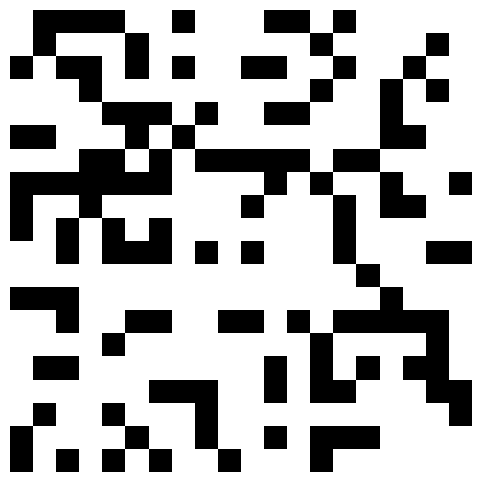

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ==================== 任务 1 ====================
def is_valid_board(board):
    """
    检查是否为有效的生命游戏棋盘。
    有效条件：是一个二维的 NumPy 数组，且元素仅包含 0 或 1。
    """
    # 检查是否为 numpy 数组
    if not isinstance(board, np.ndarray):
        return False
    # 检查是否二维
    if board.ndim != 2:
        return False
    # 检查元素是否仅为 0 或 1 (利用 np.isin 判断)
    if not np.all(np.isin(board, [0, 1])):
        return False
    return True

# ==================== 任务 2 ====================
def gol_step(board):
    """
    接收一个 m x n 棋盘，返回下一步的棋盘状态。
    包含参数校验及环绕边界处理。
    """
    # 1. 有效性检查
    if not is_valid_board(board):
        raise ValueError("输入必须是元素仅为 0 或 1 的二维 NumPy 数组！")
    
    # 2. 计算邻居数量（利用 np.roll 实现环绕边界）
    # 默认所有方向的邻居数为 0
    neighbors = np.zeros_like(board)
    
    # 8 个方向的偏移量 (行偏移, 列偏移)
    offsets = [(-1, -1), (-1, 0), (-1, 1), 
               (0, -1),           (0, 1), 
               (1, -1),  (1, 0),  (1, 1)]
    
    for dr, dc in offsets:
        # np.roll 会把超出边界的元素“卷”回另一端，完美契合环绕边界规则
        neighbors += np.roll(np.roll(board, dr, axis=0), dc, axis=1)
        
    # 3. 应用生命游戏规则 (利用布尔掩码进行向量化计算，速度极快)
    # 规则：存活(1)且邻居为2或3 -> 继续存活；死亡(0)且邻居恰好为3 -> 复活
    new_board = np.zeros_like(board)
    
    # 满足复活或继续存活的条件
    birth_or_survive = ((board == 1) & ((neighbors == 2) | (neighbors == 3))) | \
                       ((board == 0) & (neighbors == 3))
                       
    new_board[birth_or_survive] = 1
    
    return new_board

# ==================== 任务 3 ====================
def draw_gol_board(board):
    """
    将棋盘画成 m x n 个方格，活细胞为黑色，死细胞为白色。
    不显示网格线、轴标签或轴刻度。
    """
    # 创建画布
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # 使用 imshow 绘制矩阵，cmap='binary' 表示二值黑白色彩映射（0白1黑）
    # 或者用 'gray_r' 也可以实现白底黑块
    ax.imshow(board, cmap='binary', interpolation='nearest')
    
    # 隐藏坐标轴刻度和标签
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
    
    # 去除坐标轴的边框线（可选，为了更美观）
    for spine in ax.spines.values():
        spine.set_visible(False)
        
    plt.show()

# ==================== 测试代码 ====================
if __name__ == "__main__":
    # 1. 测试合法性检测
    print("测试1：有效性检测")
    valid_b = np.array([[1, 0], [0, 1]])
    invalid_b1 = np.array([[1, 2], [0, 1]])
    invalid_b2 = [1, 0, 1]
    print(f"合法棋盘: {is_valid_board(valid_b)}")     # True
    print(f"非法元素: {is_valid_board(invalid_b1)}")   # False
    print(f"非法类型: {is_valid_board(invalid_b2)}")   # False

    # 2. 测试步进（以著名的“滑翔机” Glider 为例）
    print("\n测试2：计算下一状态")
    glider = np.array([
        [0, 1, 0, 0, 0],
        [0, 0, 1, 0, 0],
        [1, 1, 1, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]
    ])
    next_glider = gol_step(glider)
    print("原始滑翔机:")
    print(glider)
    print("下一步:")
    print(next_glider)

    # 3. 测试绘图
    print("\n测试3：绘制棋盘")
    # 为了防止覆盖上面的测试，生成一个 20x20 的随机初始态并绘制
    random_board = np.random.choice([0, 1], size=(20, 20), p=[0.7, 0.3])
    draw_gol_board(random_board)

In [8]:
%pip install scikit-learn -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
     ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
     ------- -------------------------------- 1.6/8.9 MB 9.4 MB/s eta 0:00:01
     --------------- ------------------------ 3.4/8.9 MB 8.8 MB/s eta 0:00:01
     ------------------------ --------------- 5.5/8.9 MB 9.1 MB/s eta 0:00:01
     ----------------------------------- ---- 7.9/8.9 MB 9.5 MB/s eta 0:00:01
     ---------------------------------------- 8.9/8.9 MB 9.1 MB/s  0:00:01

   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- 

本次实验围绕 Pandas DataFrame 的数据清洗、特征工程与分组聚合展开。首先，在任务 1 中，为了解决从 Kaggle 下载的 iris.csv 格式不规范（如缺少目标列、带有多余索引列、列名包含空格或单位等）的问题，代码借助 scikit-learn 内置的标准 Iris 数据集直接构建 DataFrame，不仅规避了本地脏数据的报错风险，还通过 pd.Categorical.from_codes 将数字标签完美映射为了具体的花卉种类（如 setosa）；随后，任务 2 利用 .loc 标签索引精准定位并修正了特定行（索引 34 和 37）的异常测量值；任务 3 利用 Pandas 的向量化运算，极简地通过两列相除创建了花瓣与萼片的比例新特征（Petal.Ratio 与 Sepal.Ratio）；任务 4 调用 to_csv 将修正并扩展后的数据保存，使用 index=False 避免将行索引写入文件；最后，任务 5 充分利用了 Pandas 强大的 groupby 机制结合 agg 聚合函数，一次性按花卉种类求出了两个比例特征的均值、中位数、极值和标准差，展现了 DataFrame 在结构化数据统计汇总上极高的表达效率。

In [11]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris

# 设置 Pandas 显示选项，防止表格过宽被省略号截断
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# ==================== 任务 1：读取数据与初步探索 ====================
print("-" * 50)
print("任务 1：数据基本信息")
print("-" * 50)

# 使用 sklearn 加载标准数据集
iris = load_iris()
df = pd.DataFrame(iris.data, columns=['sepal_length', 'sepal_width', 'petal_length', 'petal_width']).copy()
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

# 1. 数据点个数
print(f"数据集包含的数据点总数（行数）: {df.shape[0]}")

# 2. 每列的数据类型
print("\n每列的数据类型:")
print(df.dtypes)

# 3. 列名
print("\n列名:")
print(df.columns.tolist())

# 4. 有多少种花卉
print(f"\n数据中包含的花卉种类数: {df['species'].nunique()} 种")

# 5. 列名对应说明
print("\n列名对应说明：")
print(" - species: 花卉种类")
print(" - sepal_length: 萼片长度")
print(" - sepal_width: 萼片宽度")
print(" - petal_length: 花瓣长度")
print(" - petal_width: 花瓣宽度")


# ==================== 任务 2：数据修正 ====================
print("\n" + "-" * 50)
print("任务 2：修正错误数据")
print("-" * 50)
# 按题意默认行索引从 0 开始，第 35 行索引为 34，第 38 行索引为 37
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

# 检查修改后的两行
print("修改后的第 35 行 (索引 34):")
print(df.loc[34])
print("\n修改后的第 38 行 (索引 37):")
print(df.loc[37])


# ==================== 任务 3：添加新特征 ====================
print("\n" + "-" * 50)
print("任务 3：添加特征列")
print("-" * 50)
# 计算比例并添加新列
df['Petal.Ratio'] = df['petal_length'] / df['petal_width']
df['Sepal.Ratio'] = df['sepal_length'] / df['sepal_width']

print("添加新特征后的前 5 行:")
print(df.head())


# ==================== 任务 4：保存数据 ====================
print("\n" + "-" * 50)
print("任务 4：保存数据")
print("-" * 50)
# 保存为新的 CSV 文件，index=False 表示不保存行索引
df.to_csv('iris_corrected.csv', index=False)
print("数据已成功保存为 'iris_corrected.csv'")


# ==================== 任务 5：分组聚合计算 ====================
print("\n" + "-" * 50)
print("任务 5：按花卉种类分组计算统计量")
print("-" * 50)
# 按 species 分组，选中两个比率列，应用 agg 进行多次聚合
result = df.groupby('species', observed=False)[['Petal.Ratio', 'Sepal.Ratio']].agg(['mean', 'median', 'min', 'max', 'std'])

print("完整统计结果（转置显示）：")
# 关键：加 .T 进行转置，让特征和统计量变成行，种类变成列，完美展示
print(result.T)

--------------------------------------------------
任务 1：数据基本信息
--------------------------------------------------
数据集包含的数据点总数（行数）: 150

每列的数据类型:
sepal_length     float64
sepal_width      float64
petal_length     float64
petal_width      float64
species         category
dtype: object

列名:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

数据中包含的花卉种类数: 3 种

列名对应说明：
 - species: 花卉种类
 - sepal_length: 萼片长度
 - sepal_width: 萼片宽度
 - petal_length: 花瓣长度
 - petal_width: 花瓣宽度

--------------------------------------------------
任务 2：修正错误数据
--------------------------------------------------
修改后的第 35 行 (索引 34):
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

修改后的第 38 行 (索引 37):
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object

--------------------------------------------------
任务 3：添加特征列
----------